<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/_banners/opim5512_banner.svg" alt="OPIM 5512 banner" width="100%">

# A09 · Forecasting Tomorrow's Peak: Connecticut Electricity from Six Messy Weather Stations
**Individual assignment · Module 4 (Time Series) · 100 points (+5 bonus) · due Friday, November 6, 11:59 PM**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drdave-teaching/OPIM5512-notebooks/blob/main/Module4/A09_Peak_Forecast_STARTER.ipynb)

Utilities and grid operators care most about the **peak**: the single highest hour of the day. Peaks decide how many
power plants must be ready, and they drive a big part of everyone's electricity bill. Your job: every evening, forecast
**tomorrow's peak load** for Connecticut, in MW.

Lab 5 handed you clean data from one airport. Real forecasting starts messier: ISO New England combines several weather
stations into one Connecticut temperature, and real sensors break. You get **raw reports from six Connecticut airports**,
three years of them, and the hourly Connecticut load. **We planted five realistic sensor problems** in the weather data
(the kind that really happen). Find them, fix them, and defend your choices.

| Part | Points | What you do |
|---|---|---|
| **1. EDA** | 10 | Look at the raw station data and at three years of daily peaks |
| **2. Clean** | 25 | Find and fix the five planted problems, one report per hour, combine six stations into one Connecticut temperature |
| **3. Features** | 15 | The window method (lags, rolling windows) + TSFresh features from each day's 24 hours |
| **4. Walk-forward validation** | 25 | Baselines, a model trained once vs a model retrained every month, and: did six stations beat one? |
| **5. Interpret** | 15 | Permutation importance (top 10, boxplot) and partial dependence for the top 3 features |
| **6. Conclusions** | 10 | Five bullets: what you learned |
| **Bonus** | +5 | Peak alerts: could your model warn about the hottest days? |

**Rules of the road**
- Runs on **free Colab** in about 5 to 10 minutes. No Google Cloud, no Kaggle, no downloads to your computer.
- Write your own code in the `YOUR CODE HERE` cells (Claude and Gemini are great tutors: ask them to explain, then type it
  yourself). Keep everything that's given.
- **No leakage across time.** A forecast made on the evening of day *d* may use anything up to the end of day *d*, plus the
  **weather forecast** for tomorrow. (We use tomorrow's actual weather as a stand-in for its forecast, like Lab 5.)
- Submit your **fully executed** `.ipynb` on HuskyCT (Module 4, Week 4.2, Submit A09).

# Setup (run me)

In [1]:
!pip install -q tsfresh

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/"
STATIONS = {"BDL": "Bradley (Windsor Locks)", "HFD": "Hartford-Brainard", "BDR": "Bridgeport (Sikorsky)",
            "HVN": "New Haven (Tweed)", "GON": "Groton-New London", "DXR": "Danbury"}
SEED = 5512
print("Ready.")

Ready.


# Part 1 · EDA (10 points)

## 1a. The raw weather
One file, six stations, every report (routine reports at :51 past the hour, plus "special" reports when the weather
changes fast), in UTC. Columns: `tmpf` temperature (°F), `dwpf` dew point (°F), `relh` relative humidity (%), `sknt`
wind (knots), `p01i` rain in the last hour (inches, `T` = trace). `M` means missing. Everything is read as **text** on
purpose, so nothing gets silently converted before you look.

In [2]:
raw = pd.read_csv(DATA + "a09/ct_airports_asos_2023_2025.csv", dtype=str, keep_default_na=False)
print(len(raw), "reports")
raw.head()

200859 reports


,station,valid,tmpf,dwpf,relh,sknt,p01i
0,BDL,2022-12-25 00:51,12.90,-4.00,46.02,17.00,0.00
1,BDL,2022-12-25 01:51,12.00,-3.00,50.47,11.00,0.00
2,BDL,2022-12-25 02:51,12.90,-4.00,46.02,13.00,0.00
3,BDL,2022-12-25 03:51,12.90,-3.00,48.50,16.00,0.00
4,BDL,2022-12-25 04:51,12.90,-3.00,48.50,16.00,0.00


**Your turn (1a):** how many reports does each station have, what is the first and last report time, and what does
one station's temperature look like over one week? Pick any station and any week.

         count                       min                       max
station                                                           
BDL      32650 2022-12-25 00:51:00+00:00 2026-01-07 23:51:00+00:00
BDR      33016 2022-12-25 00:52:00+00:00 2026-01-07 23:52:00+00:00
DXR      34245 2022-12-25 00:53:00+00:00 2026-01-07 23:53:00+00:00
GON      34225 2022-12-25 00:56:00+00:00 2026-01-07 23:56:00+00:00
HFD      34121 2022-12-25 00:53:00+00:00 2026-01-07 23:53:00+00:00
HVN      32602 2022-12-25 00:53:00+00:00 2026-01-07 23:53:00+00:00


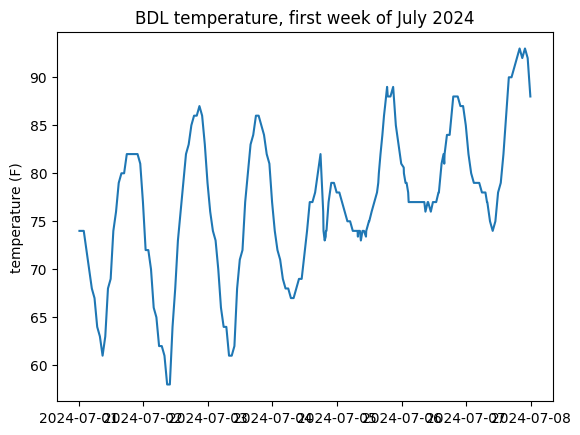

In [3]:
raw["valid_utc"] = pd.to_datetime(raw["valid"], utc=True)
# YOUR CODE HERE: reports per station, first and last report time per station (hint: groupby + agg)
print(raw.groupby("station")["valid_utc"].agg(["count", "min", "max"]))

# YOUR CODE HERE: plot one station's temperature for one week (hint: pd.to_numeric(..., errors="coerce"))
bdl = raw[raw["station"] == "BDL"]
temp = pd.to_numeric(bdl["tmpf"], errors="coerce")

week = (bdl["valid_utc"] >= "2024-07-01") & (bdl["valid_utc"] < "2024-07-08")

plt.plot(bdl["valid_utc"][week], temp[week])
plt.title("BDL temperature, first week of July 2024")
plt.ylabel("temperature (F)")
plt.show()

## 1b. The load and the target
Connecticut hourly load from ISO New England (the same file as Lab 5). `begin_date` is local time **with its UTC offset**,
so daylight saving is unambiguous. We convert to UTC, then give every hour its **Connecticut day**: the peak is the highest
hour of each local calendar day.

In [4]:
load_raw = pd.read_csv(DATA + "raw/ct_hourly_load_2023_2025_raw.csv")
load = pd.DataFrame({"hour_utc": pd.to_datetime(load_raw["begin_date"], utc=True), "load_mw": load_raw["load_mw"]})
load = load.drop_duplicates("hour_utc").set_index("hour_utc").sort_index()
load["local_day"] = load.index.tz_convert("America/New_York").tz_localize(None).normalize()
daily_peak = load.groupby("local_day")["load_mw"].max()
print(len(load), "hours ->", len(daily_peak), "days")

26304 hours -> 1096 days


**Your turn (1b):** plot the daily peak for all three years, and print the 5 highest peak days. What do they have
in common (look at the dates)?

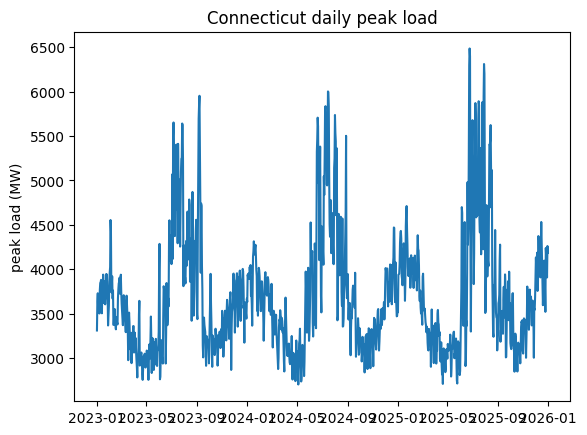

local_day
2025-06-24    6485.781
2025-06-25    6397.898
2025-07-29    6310.680
2025-06-23    6295.551
2025-07-30    6199.224
Name: load_mw, dtype: float64


In [5]:
# YOUR CODE HERE: plot daily_peak, then print the 5 highest days
plt.plot(daily_peak.index, daily_peak.values)
plt.title("Connecticut daily peak load")
plt.ylabel("peak load (MW)")
plt.show()

print(daily_peak.nlargest(5))

*Your answer (1b, one or two sentences):*

All five are summer weekdays in 2025, and they come in two runs: June 23-25 and July 29-30. That makes sense to me, since heat waves last a few days and offices are open on weekdays, so the hottest stretches push the peak up several days in a row instead of just once.

# Part 2 · Clean (25 points)

Step by step. Each step is short; the thinking is the hard part. Write down what you find.

## 2a. Text to numbers
`M` becomes missing, `T` (trace of rain) becomes a tiny amount (0.001 in), everything else becomes a number.

In [22]:
NUMBER_COLUMNS = ["tmpf", "dwpf", "relh", "sknt", "p01i"]
wx = raw.copy()
wx["p01i"] = wx["p01i"].replace("T", "0.001")
for column in NUMBER_COLUMNS:
    wx[column] = pd.to_numeric(wx[column].replace("M", ""), errors="coerce")
wx[NUMBER_COLUMNS].describe().round(1)

,tmpf,dwpf,relh,sknt,p01i
count,200196.0,199864.0,199864.0,198845.0,200839.0
mean,53.9,44.1,72.4,6.3,0.0
std,19.9,18.3,19.7,4.5,0.0
min,-99.0,-29.0,9.6,0.0,0.0
25%,41.0,30.9,57.0,3.0,0.0
50%,54.0,45.0,76.1,6.0,0.0
75%,68.0,59.0,89.5,9.0,0.0
max,999.0,81.0,100.0,143.0,2.0


## 2b. Planted problems: find all five
Real sensors break in a handful of typical ways. Look for each one below. For each problem you find, print **the station,
the dates, how many reports**, and fix it. Hints, one per problem type:
1. **Exact duplicate reports** (`duplicated()`).
2. **Impossible values** (no Connecticut airport has reached 120 °F or −40 °F).
3. **A stuck sensor**: the temperature repeats the exact same value for a day or more while the dew point keeps changing
   (on the hourly grid, real temperatures never sit still that long: the longest natural run here is about 16 hours).
4. **Wrong units**: for several days one station reads far colder than all the others (compare each station with the
   median of the six, hour by hour). What unit would make those numbers sensible?
5. **An outage**: a station with no reports at all for days.

Problems 1, 2 and 4 are easiest to find in the raw reports (2b). Problems 3 and 5 are easiest once every station is on an
hourly grid with one report per hour (2c): special reports break up a stuck run, and a missing day only shows up on a grid.

Fix what can be fixed honestly (a unit mistake can be converted back), and set to missing what can't (a stuck reading
carries no information). Missing values get filled later, and with six stations, one missing station is no disaster.

In [23]:
# Problem 1: exact duplicates (YOUR CODE HERE: count them, print station and dates, drop them)
dupes = wx[wx.duplicated()]
print("duplicate reports:", len(dupes))
print(dupes["station"].value_counts())
print("dates:", dupes["valid"].min(), "to", dupes["valid"].max())
wx = wx.drop_duplicates()

# Problem 2: impossible values (YOUR CODE HERE: find temperatures above 120 or below -40, print them, set them to missing)
bad = (wx["tmpf"] > 120) | (wx["tmpf"] < -40)
print("impossible temps:", bad.sum())
print(wx.loc[bad, ["station", "valid", "tmpf"]])
wx.loc[bad, "tmpf"] = np.nan

duplicate reports: 979
station
HFD    979
Name: count, dtype: int64
dates: 2024-03-01 00:53 to 2024-03-31 23:53
impossible temps: 35
       station             valid   tmpf
100149     GON  2023-01-01 06:56  999.0
100392     GON  2023-01-08 08:56  -99.0
100768     GON  2023-01-20 19:56  999.0
104300     GON  2023-05-17 13:56  999.0
104585     GON  2023-05-27 10:56  999.0
104695     GON  2023-05-31 14:06  999.0
105932     GON  2023-07-05 00:46  999.0
107367     GON  2023-08-15 04:56  999.0
107821     GON  2023-08-29 04:56  -99.0
109329     GON  2023-10-14 03:56  999.0
109829     GON  2023-10-31 10:56  999.0
112069     GON  2024-01-10 08:30  999.0
112140     GON  2024-01-13 00:56  -99.0
112970     GON  2024-02-08 01:56  -99.0
113165     GON  2024-02-13 15:18  999.0
115203     GON  2024-04-18 16:56  999.0
115430     GON  2024-04-27 12:56  -99.0
116356     GON  2024-05-24 07:54  -99.0
116679     GON  2024-06-02 09:56  999.0
117292     GON  2024-06-23 10:31  999.0
118033     GON  2024-07-13 

In [26]:
# Problem 4: wrong units (YOUR CODE HERE)
wx["hour"] = pd.to_datetime(wx["valid"], utc=True).dt.round("h")

temp = wx.groupby(["hour", "station"])["tmpf"].mean().unstack()
diff = temp.sub(temp.median(axis=1), axis=0)

daily = diff.resample("D").mean()
print(daily[(daily < -20).any(axis=1)].round(1))

# fix: DXR reported Celsius into the Fahrenheit column
mask = (wx["station"] == "DXR") & (wx["hour"] >= "2025-01-13") & (wx["hour"] < "2025-01-18")
print("reports fixed:", mask.sum())
wx.loc[mask, "tmpf"] = wx.loc[mask, "tmpf"] * 9 / 5 + 32

station                    BDL  BDR   DXR  GON  HFD  HVN
hour                                                    
2025-01-13 00:00:00+00:00  0.9  2.9 -31.1 -2.1 -0.5  3.0
2025-01-14 00:00:00+00:00 -0.4  0.5 -32.4 -0.3  0.3  2.2
2025-01-15 00:00:00+00:00 -0.2  1.0 -29.6 -0.2  0.0  2.5
2025-01-16 00:00:00+00:00 -0.2  1.1 -30.1  0.0 -0.6  3.2
2025-01-17 00:00:00+00:00 -0.1  0.2 -31.5  0.3 -0.6  1.9
reports fixed: 128


*Your notes (2b): what did you find for each of the five problems, and why did you fix each one the way you did?*

1. Duplicates: 979 exact copies at HFD, March 2024. Dropped with drop_duplicates(), keeping the first copy. A repeated report adds nothing and would double-count those hours on the grid.

2. Impossible values: 35 readings at GON were 999 or -99, spread across all three years. Those are no-data codes, not temperatures. Set to NaN rather than deleting the rows, since the other columns are still good.

3. Stuck sensor: HVN sat at the same temperature for 36 hours straight, from 2024-07-08 01:00 to 2024-07-09 12:00 UTC, even though its dew point kept changing. I set those hours to NaN. The number looks fine but the sensor clearly wasn't measuring anything, so there's nothing to save.

4. Wrong units: DXR ran ~30F below the other five from Jan 13-17, 2025, which matches the Celsius-to-Fahrenheit offset at freezing. Converted 128 reports back with C x 9/5 + 32 instead of dropping them, since only the unit was wrong. Dew point was within 2F of the median, so I left it alone.

5. Outage: BDR went dark for 96 hours, 2023-08-14 01:00 to 2023-08-18 00:00 UTC. Nothing to fix here, the station just wasn't reporting, so I left it missing. The other five stations still cover that week.

## 2c. One report per hour per station, on a full grid
The same rule as Lab 5: round each report to the nearest hour (10:51 → 11:00), keep the routine :51 report when there is
one (otherwise the report closest to the hour), then line every station up on the full list of hours. Hours with no report
become missing. Then look for the stuck sensor (problem 3) and the outage (problem 5).

In [28]:
# YOUR CODE HERE: one report per (station, hour), then pivot temperature and dew point into
#   temp: one column per station, one row per UTC hour on the full grid (use the START and END below)
#   dew:  the same for dew point
START = pd.Timestamp("2023-01-01 00:00", tz="America/New_York").tz_convert("UTC") - pd.Timedelta(hours=72)
END = pd.Timestamp("2025-12-31 23:00", tz="America/New_York").tz_convert("UTC") + pd.Timedelta(hours=72)
grid = pd.date_range(START, END, freq="h")

wx["minutes_off"] = (pd.to_datetime(wx["valid"], utc=True) - wx["hour"]).abs()
one = wx.sort_values("minutes_off").drop_duplicates(["station", "hour"], keep="first")

temp = one.pivot(index="hour", columns="station", values="tmpf").reindex(grid)
dew = one.pivot(index="hour", columns="station", values="dwpf").reindex(grid)
print(temp.shape)

# YOUR CODE HERE (problem 3): for each station, find runs where the temperature is identical 24+ hours in a row; set them to missing.
# Hint: a new run starts whenever the value changes from the hour before: run_id = (values != values.shift()).cumsum()
for st in temp.columns:
    v = temp[st]
    run_id = (v != v.shift()).cumsum()
    length = run_id.map(run_id.value_counts())
    stuck = (length >= 24) & v.notna()
    if stuck.sum():
        print(st, "stuck hours:", stuck.sum(), "|", v[stuck].index.min(), "to", v[stuck].index.max())
    temp.loc[stuck, st] = np.nan

# YOUR CODE HERE (problem 5): for each station, find its longest run of missing hours. Which station had an outage, and when?
for st in temp.columns:
    miss = temp[st].isna()
    run_id = (miss != miss.shift()).cumsum()
    length = run_id.map(run_id.value_counts())
    longest = length[miss].max()
    gap = miss & (length == longest)
    print(st, "longest gap:", longest, "hours |", temp.index[gap].min(), "to", temp.index[gap].max())

(26448, 6)
HVN stuck hours: 36 | 2024-07-08 01:00:00+00:00 to 2024-07-09 12:00:00+00:00
BDL longest gap: 2 hours | 2024-03-21 21:00:00+00:00 to 2024-03-21 22:00:00+00:00
BDR longest gap: 96 hours | 2023-08-14 01:00:00+00:00 to 2023-08-18 00:00:00+00:00
DXR longest gap: 10 hours | 2024-07-01 02:00:00+00:00 to 2024-07-01 11:00:00+00:00
GON longest gap: 18 hours | 2025-10-26 22:00:00+00:00 to 2025-10-27 15:00:00+00:00
HFD longest gap: 10 hours | 2023-09-22 17:00:00+00:00 to 2023-09-23 02:00:00+00:00
HVN longest gap: 36 hours | 2024-07-08 01:00:00+00:00 to 2024-07-09 12:00:00+00:00


## 2d. Fill short gaps, then combine six stations into one Connecticut temperature
Fill each station's short gaps (6 hours at most) with time interpolation. Then the **Connecticut temperature** is the
average of the stations that reported that hour, so a long outage at one station simply means five stations that week.
Do the same for dew point. Finally: how different is the Connecticut average from Bradley alone?

In [29]:
# YOUR CODE HERE: interpolate short gaps (limit=6), then build a table "weather" (index = grid) with columns
#   ct_temp_f, ct_dewpoint_f        (average across stations)
#   bdl_temp_f, bdl_dewpoint_f      (Bradley alone, for a comparison in Part 4)
# and check: no missing values left. How different is Bradley from the six-station average?
temp = temp.interpolate(method="time", limit=6)
dew = dew.interpolate(method="time", limit=6)

weather = pd.DataFrame({
    "ct_temp_f": temp.mean(axis=1),
    "ct_dewpoint_f": dew.mean(axis=1),
    "bdl_temp_f": temp["BDL"],
    "bdl_dewpoint_f": dew["BDL"],
})

weather = weather.interpolate(method="time", limit_direction="both")
print("missing values left:", weather.isna().sum().sum())

gap = weather["bdl_temp_f"] - weather["ct_temp_f"]
print("Bradley minus CT average: mean", round(gap.mean(), 2),
      "| biggest gap", round(gap.abs().max(), 1), "F")
print("hours more than 5F apart:", (gap.abs() > 5).sum())

missing values left: 0
Bradley minus CT average: mean -0.6 | biggest gap 16.0 F
hours more than 5F apart: 1836


# Part 3 · Features (15 points)

## 3a. One row per day
The forecast is made on the evening of day *d*, for day *d+1*. First, a daily table (Connecticut days): the peak, and the
daily weather (high, low, average, highest dew point) from the Connecticut average and from Bradley alone.

In [30]:
hourly_all = load[["load_mw", "local_day"]].join(weather, how="left")
daily = hourly_all.groupby("local_day").agg(
    peak_mw=("load_mw", "max"),
    ct_tmax=("ct_temp_f", "max"), ct_tmin=("ct_temp_f", "min"), ct_tmean=("ct_temp_f", "mean"),
    ct_dewmax=("ct_dewpoint_f", "max"),
    bdl_tmax=("bdl_temp_f", "max"), bdl_tmin=("bdl_temp_f", "min"), bdl_tmean=("bdl_temp_f", "mean"),
    bdl_dewmax=("bdl_dewpoint_f", "max"))
print(len(daily), "days")
daily.head()

1096 days


,peak_mw,ct_tmax,ct_tmin,ct_tmean,ct_dewmax,bdl_tmax,bdl_tmin,bdl_tmean,bdl_dewmax
local_day,,,,,,,,,
2023-01-01,3309.992,52.833333,40.333333,47.940972,49.166667,50.0,35.0,45.541667,49.0
2023-01-02,3636.387,48.833333,31.483333,38.897222,38.000000,46.0,30.0,36.283333,37.0
2023-01-03,3729.076,46.166667,36.966667,42.976389,44.666667,40.0,28.9,36.533333,38.0
2023-01-04,3533.534,54.166667,44.333333,48.770833,49.000000,47.0,39.0,42.500000,43.0
2023-01-05,3667.692,47.500000,42.333333,45.937500,45.666667,46.0,40.0,43.333333,43.0


## 3b. The window method
Every feature must be known on the evening of day *d* (or come from tomorrow's weather forecast). Build, for target day
*d+1*:
- **Tomorrow's calendar:** day of week, month, weekend, federal holiday.
- **Tomorrow's weather "forecast":** high, low, average, highest dew point (Connecticut average).
- **Heat buildup:** the average high of the last two days and tomorrow (heat waves get worse as buildings heat up).
- **Lags of the target:** today's peak (`peak_lag1`), and the peak on the same weekday last week (`peak_lag7`, which is
  6 days before today), plus the average peak of the last 7 days.

Use `shift()`: `daily["peak_mw"].shift(1)` lines yesterday's value up with today's row. Name the target column `target`.

In [31]:
from pandas.tseries.holiday import USFederalHolidayCalendar
holidays = USFederalHolidayCalendar().holidays(start="2022-01-01", end="2026-12-31")

# YOUR CODE HERE: build "rows" (index = the day being forecast) with the column "target" (that day's peak)
# and the window features listed above. Keep their names in a list called WINDOW_FEATURES. Drop rows with missing values.
rows = pd.DataFrame(index=daily.index)
rows["target"] = daily["peak_mw"]

# tomorrow's calendar (the day being forecast)
rows["dayofweek"] = rows.index.dayofweek
rows["month"] = rows.index.month
rows["is_weekend"] = (rows.index.dayofweek >= 5).astype(int)
rows["is_holiday"] = rows.index.isin(holidays).astype(int)

# tomorrow's weather forecast
rows["tmax"] = daily["ct_tmax"]
rows["tmin"] = daily["ct_tmin"]
rows["tmean"] = daily["ct_tmean"]
rows["dewmax"] = daily["ct_dewmax"]

# heat buildup: average high of the last two days and tomorrow
rows["heat_buildup"] = daily["ct_tmax"].rolling(3).mean()

# lags of the target
rows["peak_lag1"] = daily["peak_mw"].shift(1)
rows["peak_lag7"] = daily["peak_mw"].shift(7)
rows["peak_mean7"] = daily["peak_mw"].shift(1).rolling(7).mean()

WINDOW_FEATURES = ["dayofweek", "month", "is_weekend", "is_holiday",
                   "tmax", "tmin", "tmean", "dewmax", "heat_buildup",
                   "peak_lag1", "peak_lag7", "peak_mean7"]

rows = rows.dropna()
print(len(rows), "rows |", len(WINDOW_FEATURES), "features")
rows.head()

1089 rows | 12 features


,target,dayofweek,month,is_weekend,is_holiday,tmax,tmin,tmean,dewmax,heat_buildup,peak_lag1,peak_lag7,peak_mean7
local_day,,,,,,,,,,,,,
2023-01-08,3766.526,6,1,1,0,38.333333,27.966667,33.087847,24.816667,41.722222,3501.554,3309.992,3581.340286
2023-01-09,3845.544,0,1,0,0,43.333333,32.150000,36.640278,32.316667,42.277778,3766.526,3636.387,3646.559429
2023-01-10,3853.984,1,1,0,0,42.333333,33.650000,38.052083,27.033333,41.333333,3845.544,3729.076,3676.439000
2023-01-11,3880.424,2,1,0,0,37.666667,28.266667,33.134722,22.850000,41.111111,3853.984,3533.534,3694.283000
2023-01-12,3860.150,3,1,0,0,48.666667,33.816667,39.332639,46.333333,42.888889,3880.424,3667.692,3743.838714


## 3c. TSFresh: features from each day's 24 hours
Module 4.2's recipe: a long table with an **id** for each sequence and a **time** column to sort by. Here each **day** is
one sequence (its 23, 24 or 25 hours of load and Connecticut temperature). TSFresh summarizes each day's shape (mean,
spread, maximum, ...). Because a forecast for *d+1* may only use day *d*, **shift the TSFresh features by one day** before
joining them to `rows`. `MinimalFCParameters` keeps it fast (about a minute in Colab).

In [32]:
from tsfresh import extract_features
from tsfresh.feature_extraction import MinimalFCParameters

# YOUR CODE HERE: a long table with local_day (the id), a time column (hour number within the day), load_mw and ct_temp_f;
# extract_features(..., column_id="local_day", column_sort="time", default_fc_parameters=MinimalFCParameters());
# shift the result by ONE day, give the columns a "yday_" prefix, keep their names in TSFRESH_FEATURES, join to rows.
long = hourly_all[["local_day", "load_mw", "ct_temp_f"]].copy()
long["time"] = long.groupby("local_day").cumcount()

feats = extract_features(long, column_id="local_day", column_sort="time",
                         default_fc_parameters=MinimalFCParameters())

feats = feats.shift(1)
feats.columns = ["yday_" + c for c in feats.columns]
TSFRESH_FEATURES = list(feats.columns)

rows = rows.join(feats).dropna()
print(len(rows), "rows |", len(TSFRESH_FEATURES), "TSFresh features")

Feature Extraction: 100%|██████████| 2192/2192 [00:01<00:00, 1706.41it/s]


1089 rows | 20 TSFresh features


*Your leakage check (3c, two sentences): why must the TSFresh features be shifted by one day, and what would happen to
your test error if you forgot?*

One of the TSFresh features is a day's own max load, which is the target. Forecasting June 15 on the evening of June 14, I only have June 14's hours, so the features have to slide one day forward.

Without the shift my test error would drop to almost nothing and I'd think the model was great, when it was just reading the answer.

# Part 4 · Walk-forward validation (25 points)

## 4a. Train once vs walk forward
Lab 5 trained once on 2023-2024 and tested on 2025. Real forecasters **retrain as new data arrives**. Walk-forward
validation copies that: for each month of 2025, train on **every day before that month**, forecast the month, move on.
Compare four forecasts on the 365 days of 2025, month by month (MAE in MW):
1. **Persistence:** tomorrow's peak = today's peak (`peak_lag1`)
2. **Same weekday last week** (`peak_lag7`)
3. **Model trained once** on 2023-2024
4. **Model walked forward**, retrained every month

Use the same model settings for 3 and 4 (the given `make_model`).

In [33]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

FEATURES = WINDOW_FEATURES + TSFRESH_FEATURES


def make_model():
    return HistGradientBoostingRegressor(learning_rate=0.05, max_iter=400, max_leaf_nodes=15,
                                         min_samples_leaf=10, l2_regularization=1.0, random_state=SEED)


test = rows[rows.index.year == 2025]
train_once = rows[rows.index.year <= 2024]
print(len(train_once), "training days (2023-2024) |", len(test), "test days (2025) |", len(FEATURES), "features")

724 training days (2023-2024) | 365 test days (2025) | 32 features


In [34]:
# YOUR CODE HERE:
# 1. once_model = make_model(); fit on train_once; predict all of 2025 -> pred_once
once_model = make_model()
once_model.fit(train_once[FEATURES], train_once["target"])
pred_once = pd.Series(once_model.predict(test[FEATURES]), index=test.index)

# 2. walk forward: for each month 1..12 of 2025, train a fresh make_model() on every row BEFORE the first day of that month,
#    predict that month's rows -> pred_walk (one Series for the whole year)
pred_walk = pd.Series(index=test.index, dtype=float)

for m in range(1, 13):
    cutoff = pd.Timestamp(2025, m, 1)
    train = rows[rows.index < cutoff]
    month = test[test.index.month == m]

    model = make_model()
    model.fit(train[FEATURES], train["target"])
    pred_walk.loc[month.index] = model.predict(month[FEATURES])

# 3. a table monthly_mae: one row per month (+ an "ALL 2025" row), one column per forecast (the four above)
forecasts = {
    "persistence": test["peak_lag1"],
    "last week": test["peak_lag7"],
    "trained once": pred_once,
    "walk forward": pred_walk,
}

monthly_mae = pd.DataFrame(
    {name: [mean_absolute_error(test["target"][test.index.month == m], p[test.index.month == m])
            for m in range(1, 13)]
     for name, p in forecasts.items()},
    index=range(1, 13),
)
monthly_mae.loc["ALL 2025"] = [mean_absolute_error(test["target"], p) for p in forecasts.values()]
print(monthly_mae.round(1))

          persistence  last week  trained once  walk forward
1               176.1      339.4         103.3         103.3
2               143.1      238.5          74.3          82.1
3               141.2      194.1          75.5          71.4
4               131.4      188.7          69.4          73.1
5               114.3      147.7          64.0          74.4
6               544.9      825.2         175.0         170.7
7               597.0      743.7         225.6         187.2
8               364.7     1028.6         108.9         112.1
9               248.4      399.2         110.8         101.0
10              138.9      208.2          91.0          73.1
11              162.1      154.7          76.8          66.9
12              225.3      317.5         134.0         104.0
ALL 2025        249.6      400.2         109.4         101.7


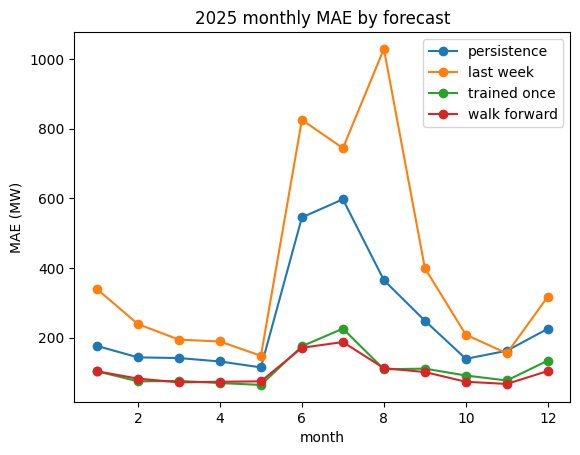

In [35]:
# YOUR CODE HERE: plot the monthly MAE of all four forecasts (one line each, months on the x axis)
for name in forecasts:
    plt.plot(range(1, 13), monthly_mae.loc[1:12, name], marker="o", label=name)

plt.title("2025 monthly MAE by forecast")
plt.xlabel("month")
plt.ylabel("MAE (MW)")
plt.legend()
plt.show()

## 4b. Did six stations beat one?
Repeat the **walk-forward** forecast with Bradley's weather (`bdl_tmax`, `bdl_tmin`, `bdl_tmean`, `bdl_dewmax`, and a
Bradley heat buildup) in place of the Connecticut average, everything else the same. Was all that cleaning worth it?

In [36]:
# YOUR CODE HERE: copy rows, swap in Bradley's daily weather (and a Bradley heat_buildup), walk forward again,
# and print both 2025 MAEs side by side
rows_bdl = rows.copy()
rows_bdl["tmax"] = daily["bdl_tmax"]
rows_bdl["tmin"] = daily["bdl_tmin"]
rows_bdl["tmean"] = daily["bdl_tmean"]
rows_bdl["dewmax"] = daily["bdl_dewmax"]
rows_bdl["heat_buildup"] = daily["bdl_tmax"].rolling(3).mean()
rows_bdl = rows_bdl.dropna()

test_bdl = rows_bdl[rows_bdl.index.year == 2025]
pred_bdl = pd.Series(index=test_bdl.index, dtype=float)

for m in range(1, 13):
    cutoff = pd.Timestamp(2025, m, 1)
    train = rows_bdl[rows_bdl.index < cutoff]
    month = test_bdl[test_bdl.index.month == m]

    model = make_model()
    model.fit(train[FEATURES], train["target"])
    pred_bdl.loc[month.index] = model.predict(month[FEATURES])

mae_six = mean_absolute_error(test["target"], pred_walk)
mae_one = mean_absolute_error(test_bdl["target"], pred_bdl)
print("six stations:", round(mae_six, 1), "MW")
print("Bradley only:", round(mae_one, 1), "MW")
print("difference:  ", round(mae_one - mae_six, 1), "MW")

six stations: 101.7 MW
Bradley only: 125.8 MW
difference:   24.0 MW


*Your answers (4a and 4b, three or four sentences): which forecast won, in which months did the model struggle most and
why, did retraining every month help, and did six stations beat one?*

The walk-forward model won at 101.7 MW, just ahead of the model trained once at 109.4, and both were far better than persistence (249.6) and same-weekday-last-week (400.2). Everyone struggled most in June and July, when the summer peaks hit 6000+ MW; those extreme days are rare, so the model has few examples to learn from and it undershoots them.

Retraining monthly helped, but not much and not evenly. January is identical since both models start with the same data, and the gap only opens up late in the year, 134.0 vs 104.0 in December, when the frozen model is working off data a full year old.

Six stations beat Bradley alone, 101.7 vs 125.8 MW, a 19% improvement. That's a bigger gain than retraining gave me, so yes, the cleaning was worth it.

# Part 5 · Interpret (15 points)
Use the **model trained once** (`once_model`) on the 2025 test days.
1. **Permutation importance, top 10 features, as a boxplot** (10 shuffles each).
2. **Partial dependence plots for the top 3 features**, and a short description of what each one shows.

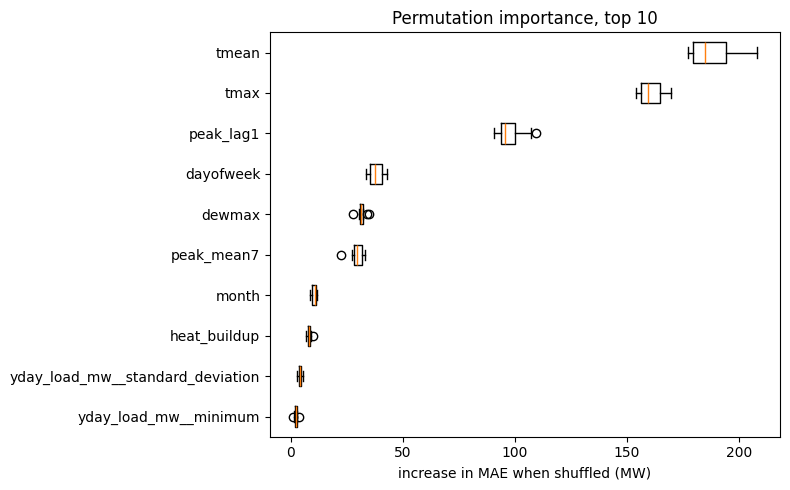

TOP3: ['tmean', 'tmax', 'peak_lag1']


In [37]:
from sklearn.inspection import permutation_importance
# YOUR CODE HERE: permutation importance on test (n_repeats=10), boxplot of the top 10, and a list TOP3
imp = permutation_importance(once_model, test[FEATURES], test["target"],
                             n_repeats=10, random_state=SEED,
                             scoring="neg_mean_absolute_error")

order = imp.importances_mean.argsort()[::-1][:10]
top10 = [FEATURES[i] for i in order]

plt.figure(figsize=(8, 5))
plt.boxplot(imp.importances[order].T, vert=False, labels=top10)
plt.gca().invert_yaxis()
plt.title("Permutation importance, top 10")
plt.xlabel("increase in MAE when shuffled (MW)")
plt.tight_layout()
plt.show()

TOP3 = top10[:3]
print("TOP3:", TOP3)

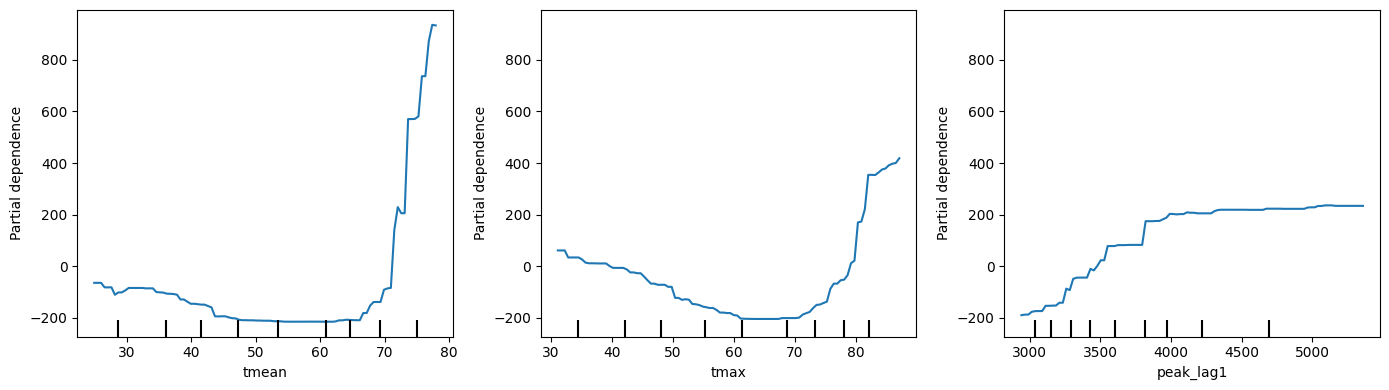

In [38]:
from sklearn.inspection import PartialDependenceDisplay
# YOUR CODE HERE: partial dependence plots for TOP3 (three panels)
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
PartialDependenceDisplay.from_estimator(once_model, test[FEATURES], TOP3, ax=ax)
plt.tight_layout()
plt.show()

*Your description (Part 5): what does each of the three partial dependence plots show? Does it make physical sense?*

tmean and tmax both look like hockey sticks: flat from about 50F to 68F, then shooting up above 70. For tmean the prediction goes from roughly -200 to +930 MW across just ten degrees. That's air conditioning switching on, and the fact that there's no matching rise on the cold end fits Connecticut, which heats with gas and oil but cools with electricity.

peak_lag1 climbs steeply from 2900 to about 3800 MW and then flattens out near +220. It's telling the model the baseline demand level. Past 4000 MW it stops mattering much, since by then the temperature features are doing the explaining.

All three make sense physically. The hockey stick is the same thing I saw in 1b, where every one of the five highest peak days was a summer day.

# Part 6 · Conclusions (10 points)
Five bullets: what you learned about cleaning real sensor data, about features for time series, about validating a
forecast honestly, and about this problem.

1. Bad sensor data doesn't look bad. The 999s and -99s stood out, but the stuck sensor at HVN and the Celsius mix-up at DXR both looked like perfectly reasonable numbers. I only found them by comparing each station against the median of the others, hour by hour.

2. How you fix something depends on whether the measurement is recoverable. DXR's Celsius readings were right, just mislabeled, so a conversion got them back. A stuck sensor and a four-day outage have nothing to recover, so missing is the honest answer.

3. Every feature has to be checkable against a clock. The TSFresh features were the easy trap, since one of them is a day's own max load. Shifting them a day was the difference between an honest model and one reading the answer.

4. Baselines matter. Persistence came in at 249.6 MW with no model at all, which is the bar anything fancier has to clear. My model got to 101.7. Retraining monthly only bought 8 MW, and almost all of it in the last few months of the year.

5. Peak load in Connecticut is an air conditioning problem. Temperature was far and away the most important feature, and the partial dependence plots are flat until about 70F and then shoot up. The six-station average beat Bradley alone by 24 MW, so averaging across the state was worth the cleaning.

# Bonus · Peak alerts (+5 points)
Grid operators issue alerts before the hottest days. Call a day an **alert day** if its peak is above the 95th percentile of
the 2023-2024 daily peaks. Using your walk-forward forecasts: how many of 2025's alert days did your model flag (forecast
above the same line), how many false alarms did it raise, and how does that compare with persistence? Show a confusion matrix.

In [39]:
# BONUS (optional): YOUR CODE HERE
from sklearn.metrics import confusion_matrix

line = rows.loc[rows.index.year <= 2024, "target"].quantile(0.95)
print("alert line:", round(line, 1), "MW")

actual = test["target"] > line
flag_model = pred_walk > line
flag_persist = test["peak_lag1"] > line

print("\nactual alert days in 2025:", actual.sum())

for name, flag in [("walk forward", flag_model), ("persistence", flag_persist)]:
    tn, fp, fn, tp = confusion_matrix(actual, flag).ravel()
    print(f"\n{name}")
    print(f"  caught: {tp} of {tp + fn}   missed: {fn}   false alarms: {fp}")
    print(f"  {pd.DataFrame([[tn, fp], [fn, tp]], index=['no alert', 'alert'], columns=['said no', 'said yes'])}")

alert line: 5149.6 MW

actual alert days in 2025: 22

walk forward
  caught: 20 of 22   missed: 2   false alarms: 1
            said no  said yes
no alert      342         1
alert           2        20

persistence
  caught: 14 of 22   missed: 8   false alarms: 8
            said no  said yes
no alert      335         8
alert           8        14


With the alert line at 5149.6 MW (the 95th percentile of 2023-2024 daily peaks), 2025 had 22 alert days. The walk-forward model flagged 20 of them and raised one false alarm. Persistence caught 14 and raised eight.

Persistence can never call the first day of a heat wave, since it just repeats yesterday. The model sees tomorrow's forecast temperature, which is what an alert actually needs.

---
**Data credits:** weather from the Iowa State Mesonet (mesonet.agron.iastate.edu) archive of NWS/FAA airport reports, with
five sensor problems planted for this assignment; load from ISO New England (iso-ne.com, ISO Express web services).